<a href="https://colab.research.google.com/github/ShanzayIQ/AI651-Assignment2/blob/main/Q2_part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI651 Assignment 2 — Question 2: Motion or Memory?
## Part 1 — Setup: data, transformations, windows, Table 1, Figure 1

Run on Colab with a **GPU runtime** (Runtime → Change runtime type → T4 GPU). Part 1 itself only needs CPU, but later parts train models.

Cells are in order — use **Runtime → Run all**.

### 0. Environment and save folder (Google Drive)

In [1]:
# Mount Drive so data, figures and later checkpoints survive Colab disconnects
from google.colab import drive
drive.mount('/content/drive')

import os
ROOT = '/content/drive/MyDrive/AI651_A2_Q2'      # change if you like
DATA_DIR = os.path.join(ROOT, 'data')
FIG_DIR  = os.path.join(ROOT, 'figures')
RES_DIR  = os.path.join(ROOT, 'results')
for d in (DATA_DIR, FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)
print('Saving everything under', ROOT)

Mounted at /content/drive
Saving everything under /content/drive/MyDrive/AI651_A2_Q2


In [2]:
import json, math, platform, time
import numpy as np
import torch
import torchvision
import cv2
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| opencv', cv2.__version__)
print('device:', device, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor())

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | opencv 5.0.0
device: cuda | Tesla T4


### 1. Load Moving MNIST and split by **video index**
`split=None` gives all 10,000 complete videos, shape `(10000, 20, 1, 64, 64)` uint8.
Split: videos 0–7999 train, 8000–8999 validation, 9000–9999 test.
Frames are kept as uint8 in memory (≈820 MB) and converted to float32/255 when used.

In [3]:
ds = torchvision.datasets.MovingMNIST(root=DATA_DIR, split=None, download=True)
videos_u8 = ds.data                      # (10000, 20, 1, 64, 64) uint8
print('all videos:', tuple(videos_u8.shape), videos_u8.dtype)

train_u8 = videos_u8[0:8000]
val_u8   = videos_u8[8000:9000]
test_u8  = videos_u8[9000:10000]
print('train', tuple(train_u8.shape), '| val', tuple(val_u8.shape), '| test', tuple(test_u8.shape))

def to_float(v_u8):
    """uint8 frames -> float32 in [0, 1]."""
    return v_u8.float() / 255.0

x0 = to_float(train_u8[0])
print('one video as float:', tuple(x0.shape), 'min', x0.min().item(), 'max', x0.max().item())

100%|██████████| 819M/819M [00:21<00:00, 37.8MB/s]


all videos: (10000, 20, 1, 64, 64) torch.uint8
train (8000, 20, 1, 64, 64) | val (1000, 20, 1, 64, 64) | test (1000, 20, 1, 64, 64)
one video as float: (20, 1, 64, 64) min 0.0 max 1.0


### 2. Transformations: mirror M, rotation R, and the 8 symmetries G
All act on the last two dims (rows, cols), so they work on a frame `(1,64,64)`, a video `(T,1,64,64)` or a batch `(B,T,1,64,64)`.
- `M`: `(Mx)[i,j] = x[i, 63-j]` → `flip` along the column axis.
- `R`: 90° anticlockwise → `torch.rot90(x, k=1, dims=(-2,-1))`.
- `g = (a, m)`: rotate by `R^a` first, then mirror if `m=1`. Inverse: `R^{-a}` when `m=0`; `MR^a` is its own inverse.

In [4]:
def mirror(x):
    return torch.flip(x, dims=(-1,))

def rotate(x, a=1):
    return torch.rot90(x, k=a % 4, dims=(-2, -1))

# The 8 elements of G as (a, m): R^a for m=0, M R^a for m=1
G = [(a, m) for m in (0, 1) for a in range(4)]

def apply_g(x, g):
    a, m = g
    y = rotate(x, a)               # rotate first ...
    return mirror(y) if m else y   # ... then mirror

def apply_g_inv(x, g):
    a, m = g
    if m:                          # M R^a is its own inverse
        return apply_g(x, g)
    return rotate(x, -a)           # (R^a)^{-1} = R^{-a}

def g_name(g):
    a, m = g
    return ('M' if m else '') + (f'R^{a}' if a else ('' if m else 'Id'))

print([g_name(g) for g in G])

['Id', 'R^1', 'R^2', 'R^3', 'M', 'MR^1', 'MR^2', 'MR^3']


### 3. Windows at speed k
Frames are numbered **1–20** (as in the handout). For start `t` and speed `k`:
inputs `t, t+k, …, t+4k`; targets `t+5k, …, t+9k`, keeping only targets ≤ 20.
The function always returns 5 target slots plus a mask, because the model always makes 5 predictions and only existing targets are scored.

In [5]:
N_FRAMES = 20

def window_frames(t, k):
    """1-indexed frame numbers used as input and as (existing) targets."""
    inp = [t + k * i for i in range(5)]
    tgt = [t + k * i for i in range(5, 10) if t + k * i <= N_FRAMES]
    assert inp[-1] <= N_FRAMES, 'input frames must exist'
    return inp, tgt

def get_window(video, t, k=1):
    """video: (20, C, H, W) or (B, 20, C, H, W).
    Returns X (.., 5, C, H, W), Y (.., 5, C, H, W) zero-padded, and mask (5,) bool for existing targets."""
    inp, tgt = window_frames(t, k)
    tdim = video.dim() - 4                 # time axis (0 for one video, 1 for a batch)
    idx = lambda frames: torch.tensor([f - 1 for f in frames], device=video.device)
    X = video.index_select(tdim, idx(inp))
    Y_exist = video.index_select(tdim, idx(tgt))
    pad_shape = list(Y_exist.shape); pad_shape[tdim] = 5 - len(tgt)
    Y = torch.cat([Y_exist, Y_exist.new_zeros(pad_shape)], dim=tdim)
    mask = torch.tensor([True] * len(tgt) + [False] * (5 - len(tgt)))
    return X, Y, mask

# Allowed start frames (handout, 'Windows at different speeds')
def allowed_starts(k, augmented):
    if not augmented:                       # models A, B: 1x only, all 5 targets exist
        assert k == 1
        return [t for t in range(1, N_FRAMES + 1) if t + 9 * k <= N_FRAMES]
    # models C, D: all 5 inputs and at least 2 targets exist
    return [t for t in range(1, N_FRAMES + 1) if t + 6 * k <= N_FRAMES]

print('normal 1x :', allowed_starts(1, False))
for k in (1, 2, 3):
    print(f'augmented {k}x:', allowed_starts(k, True))

normal 1x : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
augmented 1x: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
augmented 2x: [1, 2, 3, 4, 5, 6, 7, 8]
augmented 3x: [1, 2]


### 4. Checking the code → **Table 1**
Uses exactly the functions above (`mirror`, `rotate`, `get_window`).

In [6]:
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)              # random video
p = torch.zeros(20, 1, 64, 64)             # marker video
p[7, 0, 10, 20] = 1.0                      # (frame index 7, row 10, column 20), indices from 0

def maxdiff(a, b):
    return (a - b).abs().max().item()

def bright(v):
    f, c, r, col = (v == v.max()).nonzero()[0].tolist()
    return (f, r, col)

lhs_a, lhs_b = mirror(mirror(x)), rotate(x, 4)
lhs_c, rhs_c = mirror(rotate(mirror(x), 1)), rotate(x, -1)

# Video whose frame f is filled with the value f (frames 1..20)
fv = torch.arange(1, 21, dtype=torch.float32).view(20, 1, 1, 1).expand(20, 1, 64, 64).clone()
def frames_used(k):
    X, Y, mask = get_window(fv, t=1, k=k)
    inp = [int(X[i, 0, 0, 0]) for i in range(5)]
    tgt = [int(Y[i, 0, 0, 0]) for i in range(5) if mask[i]]
    return ', '.join(map(str, inp)) + ' / ' + ', '.join(map(str, tgt))

table1 = [
    ('(a) max|M(M(x)) - x|',        '0', f'{maxdiff(lhs_a, x):g}  (equal={torch.equal(lhs_a, x)})'),
    ('(b) max|R^4(x) - x|',         '0', f'{maxdiff(lhs_b, x):g}  (equal={torch.equal(lhs_b, x)})'),
    ('(c) max|MRM(x) - R^-1(x)|',   '0', f'{maxdiff(lhs_c, rhs_c):g}  (equal={torch.equal(lhs_c, rhs_c)})'),
    ('(d) bright pixel of M(p)',    '(7, 10, 43)', str(bright(mirror(p)))),
    ('(e) bright pixel of R(p)',    '(7, 43, 10)', str(bright(rotate(p, 1)))),
    ('(f) 1x input / target',       '1-5 / 6-10', frames_used(1)),
    ('(g) 2x input / target',       '1, 3, 5, 7, 9 / 11, 13, 15, 17, 19', frames_used(2)),
    ('(h) 3x input / target',       '1, 4, 7, 10, 13 / 16, 19', frames_used(3)),
]
print(f'{"Check":30s} | {"Expected":36s} | Yours')
print('-' * 100)
for row in table1:
    print(f'{row[0]:30s} | {row[1]:36s} | {row[2]}')

# hard assertions so later parts never run on broken functions
assert torch.equal(lhs_a, x) and torch.equal(lhs_b, x) and torch.equal(lhs_c, rhs_c)
assert bright(mirror(p)) == (7, 10, 43) and bright(rotate(p, 1)) == (7, 43, 10)
assert frames_used(1) == '1, 2, 3, 4, 5 / 6, 7, 8, 9, 10'
assert frames_used(2) == '1, 3, 5, 7, 9 / 11, 13, 15, 17, 19'
assert frames_used(3) == '1, 4, 7, 10, 13 / 16, 19'
# extra sanity: every g and its inverse
for g in G:
    assert torch.equal(apply_g_inv(apply_g(x, g), g), x), g
print('\nAll Table 1 checks passed (and g^-1(g(x)) = x for all 8 symmetries).')

with open(os.path.join(RES_DIR, 'table1.json'), 'w') as f:
    json.dump(table1, f, indent=1)

Check                          | Expected                             | Yours
----------------------------------------------------------------------------------------------------
(a) max|M(M(x)) - x|           | 0                                    | 0  (equal=True)
(b) max|R^4(x) - x|            | 0                                    | 0  (equal=True)
(c) max|MRM(x) - R^-1(x)|      | 0                                    | 0  (equal=True)
(d) bright pixel of M(p)       | (7, 10, 43)                          | (7, 10, 43)
(e) bright pixel of R(p)       | (7, 43, 10)                          | (7, 43, 10)
(f) 1x input / target          | 1-5 / 6-10                           | 1, 2, 3, 4, 5 / 6, 7, 8, 9, 10
(g) 2x input / target          | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19   | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19
(h) 3x input / target          | 1, 4, 7, 10, 13 / 16, 19             | 1, 4, 7, 10, 13 / 16, 19

All Table 1 checks passed (and g^-1(g(x)) = x for all 8 symmetries).


### 5. Is the training data already symmetric? → **Figure 1**
Farneback optical flow on the **first 50 training videos**, all 19 consecutive pairs (950 pairs), on uint8 frames, with exactly the handout's settings.
Keep pixels with intensity > 0.2 (on [0,1]) at the same location in **both** frames and flow magnitude > 0.5 px.
Direction θ = atan2(−dy, dx) in [0°, 360°): 0° = right, 90° = up on screen.

In [7]:
def farneback(prev_u8, next_u8):
    return cv2.calcOpticalFlowFarneback(prev_u8, next_u8, None, 0.5, 3, 15, 3, 5, 1.2, 0)

all_dx, all_dy = [], []
n_pairs = 0
for vid in range(50):
    frames = train_u8[vid, :, 0].numpy()           # (20, 64, 64) uint8 (= float*255)
    frames_f = frames.astype(np.float32) / 255.0
    for s in range(19):                             # pairs (x_s, x_{s+1}), s = 1..19
        flow = farneback(frames[s], frames[s + 1])  # (64, 64, 2): [..., 0] = dx (cols), [..., 1] = dy (rows)
        dx, dy = flow[..., 0], flow[..., 1]
        mag = np.sqrt(dx ** 2 + dy ** 2)
        keep = (frames_f[s] > 0.2) & (frames_f[s + 1] > 0.2) & (mag > 0.5)
        all_dx.append(dx[keep]); all_dy.append(dy[keep])
        n_pairs += 1

dx = np.concatenate(all_dx); dy = np.concatenate(all_dy)
theta = np.degrees(np.arctan2(-dy, dx)) % 360.0
speed = np.sqrt(dx ** 2 + dy ** 2)
n_kept = len(speed)
med_speed = float(np.median(speed))
print(f'frame pairs: {n_pairs} | pixels kept: {n_kept} | median speed: {med_speed:.3f} px/frame')

frame pairs: 950 | pixels kept: 103050 | median speed: 3.318 px/frame


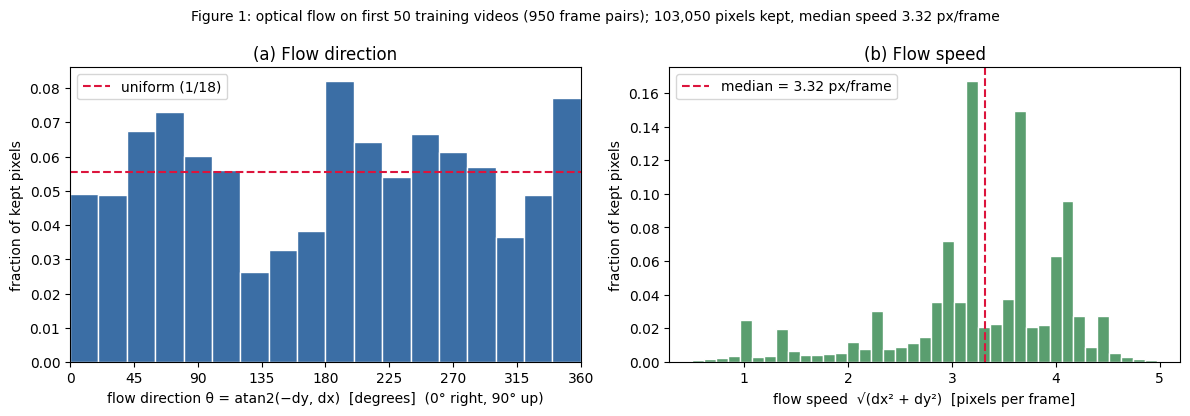

In [8]:
bins_dir = np.arange(0, 361, 20)
w = np.full(n_kept, 1.0 / n_kept)                   # fractions, not counts

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.hist(theta, bins=bins_dir, weights=w, edgecolor='white', color='#3b6ea5')
ax.axhline(1 / 18, color='crimson', ls='--', lw=1.5, label='uniform (1/18)')
ax.set_xticks(range(0, 361, 45)); ax.set_xlim(0, 360)
ax.set_xlabel('flow direction θ = atan2(−dy, dx)  [degrees]  (0° right, 90° up)')
ax.set_ylabel('fraction of kept pixels'); ax.set_title('(a) Flow direction'); ax.legend()

ax = axes[1]
smax = np.percentile(speed, 99.5)
ax.hist(speed, bins=np.linspace(0.5, smax, 40), weights=w, edgecolor='white', color='#5a9e6f')
ax.axvline(med_speed, color='crimson', ls='--', lw=1.5, label=f'median = {med_speed:.2f} px/frame')
ax.set_xlabel('flow speed  √(dx² + dy²)  [pixels per frame]')
ax.set_ylabel('fraction of kept pixels'); ax.set_title('(b) Flow speed'); ax.legend()

fig.suptitle(f'Figure 1: optical flow on first 50 training videos (950 frame pairs); '
             f'{n_kept:,} pixels kept, median speed {med_speed:.2f} px/frame', fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'figure1_flow.png'), dpi=200, bbox_inches='tight')
plt.show()

#### Numbers to help answer Q2.1
Mirroring maps a direction θ to 180° − θ; a 90° anticlockwise rotation maps θ to θ + 90°.
If the histogram is (close to) unchanged under these maps, mirrored/rotated **motion** is already familiar.
We compare the histogram with its mirrored and rotated versions (total variation distance: 0 = identical, 1 = no overlap).

In [9]:
def dir_hist(th):
    h, _ = np.histogram(th % 360, bins=bins_dir)
    return h / h.sum()

h0   = dir_hist(theta)
h_m  = dir_hist(180.0 - theta)
h_r  = dir_hist(theta + 90.0)
tv = lambda a, b: 0.5 * np.abs(a - b).sum()
print(f'TV(original, mirrored) = {tv(h0, h_m):.3f}')
print(f'TV(original, rotated)  = {tv(h0, h_r):.3f}')
print(f'TV(original, uniform)  = {tv(h0, np.full(18, 1/18)):.3f}')
print(f'max bin / min bin = {h0.max():.4f} / {h0.min():.4f}  (uniform = {1/18:.4f})')
print()
print(f'speed quartiles (px/frame): 25% {np.percentile(speed,25):.2f} | 50% {med_speed:.2f} | 75% {np.percentile(speed,75):.2f} | 95% {np.percentile(speed,95):.2f}')
print(f'2x median ≈ {2*med_speed:.2f} px/frame | 3x median ≈ {3*med_speed:.2f} px/frame')

summary = dict(n_pairs=n_pairs, n_kept=int(n_kept), median_speed=med_speed,
               tv_mirror=float(tv(h0, h_m)), tv_rotate=float(tv(h0, h_r)),
               tv_uniform=float(tv(h0, np.full(18, 1/18))))
with open(os.path.join(RES_DIR, 'figure1_stats.json'), 'w') as f:
    json.dump(summary, f, indent=1)
print('\nsaved', os.path.join(RES_DIR, 'figure1_stats.json'))

TV(original, mirrored) = 0.132
TV(original, rotated)  = 0.200
TV(original, uniform)  = 0.109
max bin / min bin = 0.0820 / 0.0263  (uniform = 0.0556)

speed quartiles (px/frame): 25% 3.00 | 50% 3.32 | 75% 3.89 | 95% 4.32
2x median ≈ 6.64 px/frame | 3x median ≈ 9.95 px/frame

saved /content/drive/MyDrive/AI651_A2_Q2/results/figure1_stats.json


#### Optional: overlay used for discussion (not a required figure)

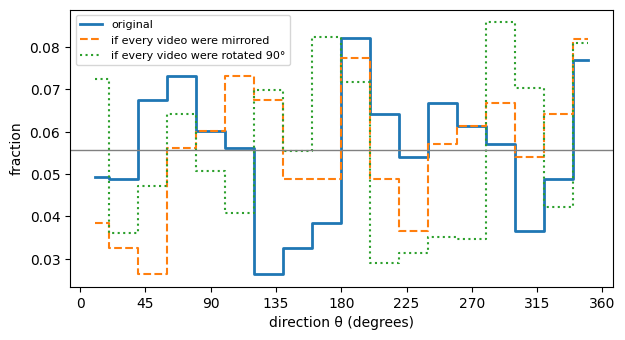

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
centers = bins_dir[:-1] + 10
ax.step(centers, h0, where='mid', label='original', lw=2)
ax.step(centers, h_m, where='mid', label='if every video were mirrored', lw=1.5, ls='--')
ax.step(centers, h_r, where='mid', label='if every video were rotated 90°', lw=1.5, ls=':')
ax.axhline(1/18, color='gray', lw=1)
ax.set_xlabel('direction θ (degrees)'); ax.set_ylabel('fraction'); ax.legend(fontsize=8)
ax.set_xticks(range(0, 361, 45)); plt.show()

### Sample training videos (sanity check)

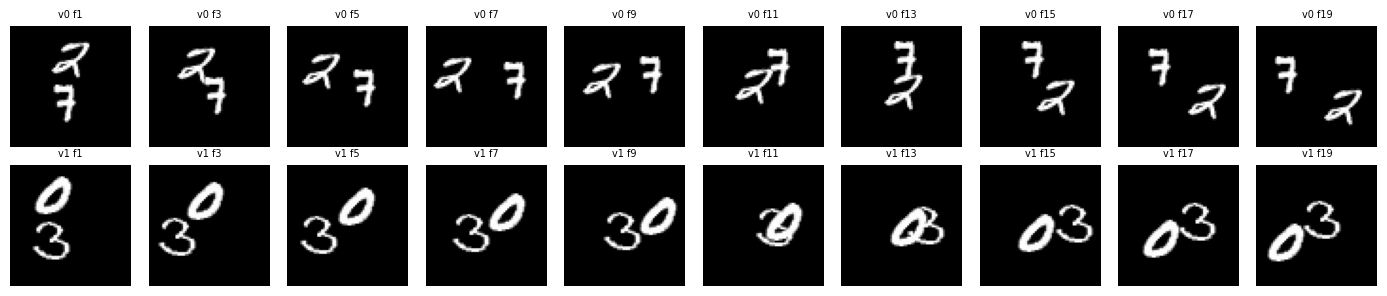

In [11]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for r, vid in enumerate([0, 1]):
    for c in range(10):
        axes[r, c].imshow(train_u8[vid, c * 2, 0], cmap='gray'); axes[r, c].axis('off')
        axes[r, c].set_title(f'v{vid} f{c*2+1}', fontsize=7)
plt.tight_layout(); plt.show()